Importing and calling ...../Fitting/GenPaths.py
added to path: ['/Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/Fitting', '/Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/PDEhelpers', '/Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling']
PROPATH variable: /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling
------------------------------------------------
['air', 'lxe', 'lxe2', 'cf4', 'green', 'red']
style object members: 	 ['col', 'ls', 'printMembers']


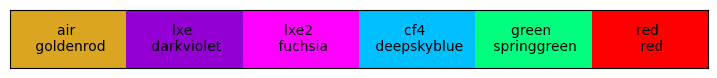

In [1]:
from GenPaths import * # this provides PROPATH which helps load stuff (and the paths to find the PDEhelpers stuff)

import pandas as pd
import matplotlib.pyplot as plt

from scipy import optimize as opt
import iminuit
from iminuit import Minuit

from PDEhelpers.OpticsDataLoader import *
import PDEhelpers.MathEquations as ME
from PDEhelpers.PhotonInfo import * # this calls DataLoader when defining init
# from PDEhelpers.PNJunction import *
import PDEhelpers.PNJunction as PNJ

import PDE_fittingTools as SS

import PDEhelpers.PDEStyle as MS
MS.ShowMyStyles() # for colors
ms = MS.MyStyleSet() # object to use like

rad2deg = 180/np.pi

# MS.ShowMyStyles() # for colors
# ms = MS.MyStyleSet() # object to use like
# ms.SetMPLcolors() # turn off with "off" option


In [2]:
## Some reflectivity equation
# 1. general scaling (to PDE_0)
# 2. divide by Fresnel term
# 3. see what we get?

---
### Analytic math

* $ff$ - 1D width of a trench (units of $\mu m$)
* $FF$ - Unitless loss per pixel
* $p$ - repeatable pixel size (length of entire pixel including surrounding $ff$)

We will write out the $FF$ as a ratio of the inner pixel size to the total pixel size

$$ FF = \frac{(p - 2ff)^2}{p^2} $$
$$ 4 ff^2 \mathbf{-4p} ff + \mathbf{(1-FF)p^2} = 0 $$
$$ ff^2 \mathbf{-p} ff + \mathbf{(1-FF)p^2/4} = 0 $$
$$ \mathbf{a}x^2 + \mathbf{b}x + \mathbf{c} = 0$$


In [3]:
def quadraticSolution(a, b, c):
    return (-b + np.sqrt(b**2 - 4*a*c))/(2*a), (-b - np.sqrt(b**2 - 4*a*c))/(2*a)

FF = 0.6
p = 50 # units of um
FF2 = 0.7
p2 = 75 # units of um

## Case A
case50 = quadraticSolution(a = 1, b = -p, c = (1-FF)*(p**2)/4)
case75 = quadraticSolution(a = 1, b = -p2, c = (1-FF2)*(p2**2)/4)

print("Case 50um: ", case50)
print("Case 75um: ", case75)

Case 50um:  (44.364916731037084, 5.635083268962916)
Case 75um:  (68.87475099502782, 6.125249004972169)


In [4]:
# after doing a bunch of math:

# angles in degrees

def l_loss(h, theta):
    theta = np.abs(theta * np.pi/180)
    return h * np.tan(theta)

def FF_theta_absolute(p, ff, h, theta):
    l = l_loss(h, theta)
    top = p - 2*ff - l
    return (top**2)/p**2

def FF_theta_relative(W, H, theta):
    # W defined as ff/p
    # H defined as h/p
    theta = np.abs(theta * np.pi/180)
    
    fixed = (1 - 2*W)**2
    var = H*np.tan(theta) * (H*np.tan(theta) + 4*W - 2)
    
    return fixed + var

ff side relative to pitch: 0.11270166537925831
height relative to pitch: 0.05
0.6000000000000001
0.6


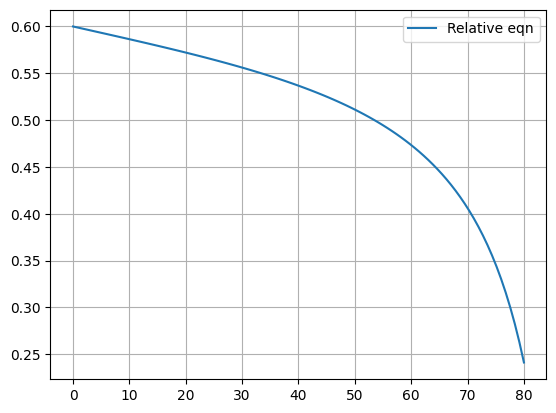

In [5]:
# from AFM measurements
p = 50

ffm = 7
Wm = ffm/p
hm = 2.5
Hm = hm/p

# calculated values. need to use this for effective model
ffc = case50[1]
Wc = ffc/p
print('ff side relative to pitch:', Wc)
Hc = hm/p
print("height relative to pitch:", Hc)

xThetas = np.linspace(0, 80, 100)

ffAbsolute = FF_theta_absolute(p, ffc, hm, xThetas)

ffRelative = FF_theta_relative(Wc, Hm, xThetas)

print(FF_theta_relative(Wc, Hc, 0))
print(FF_theta_absolute(p, ffc, hm, 0))

plt.plot(xThetas, ffRelative, label = "Relative eqn")
# plt.plot(xThetas, ffAbsolute-0.01, label = "Absolute eqn, shifted (correct!)")

plt.legend()
# plt.xlim(0, 15)
# plt.ylim(0.5, 0.62)

plt.grid()
plt.show()

---
---
### Load the data

In [6]:
fpath = os.path.join(PROPATH, "../veraData/angular_scans_VUV_feb2024")

# flist = ["HPKW_angular_190nm_-110C_0.5mm_slit_6oV.csv", "HPKW_angular_210nm_-110C_0.5mm_slit_6oV.csv", "HPKW_angular_220nm_-110C_0.5mm_slit_6oV.csv", "HPKW_angular_235nm_-110C_0.5mm_slit_6oV.csv"]

# dx_190_6V, dy_190_6V, dyErr_190_6V = np.genfromtxt(fpath+"/HPKW_angular_190nm_-110C_0.5mm_slit_1oV.csv", delimiter=",", skip_header=1)
df_190_6v = pd.read_csv(fpath+"/HPKW_angular_210nm_-110C_0.5mm_slit_6oV.csv", header=0)
print(df_190_6v.head())
print(df_190_6v.tail())

names=df_190_6v.columns
print("columns:", names)
print("unique angles:", df_190_6v[names[0]].unique())

# drop data for maximum angles (where diode is turned off)
print("max angle:", df_190_6v[names[0]].values.max())
df_190_6v = df_190_6v[df_190_6v[names[0]] < df_190_6v[names[0]].values.max()]

# get values at normal incidence
normalCurrent = df_190_6v.loc[df_190_6v[names[0]] == 0, names[1]].values[0]
normalError = df_190_6v.loc[df_190_6v[names[0]] == 0, names[2]].values[0]
print(normalCurrent)

print(names)
dx_190_6V = df_190_6v[names[0]].values
dx_190_6V *= -1 # flip sign

dy_190_6Vraw = df_190_6v[names[1]].values
dy_190_6V_norm = dy_190_6Vraw/normalCurrent # normalize to max value

dyErr_190_6V = df_190_6v[names[2]].values
dyErr_190_6V = dy_190_6V_norm * np.sqrt((dyErr_190_6V/dy_190_6Vraw)**2 + (normalError/normalCurrent)**2)

   Angle (starting from -60deg)       Current         Error
0                            14  8.339850e-11  1.602240e-11
1                           -60  2.149720e-08  3.266660e-10
2                           -58  5.194430e-08  5.791330e-10
3                           -56  8.203900e-08  6.430020e-10
4                           -54  1.099000e-07  7.032190e-10
    Angle (starting from -60deg)       Current         Error
35                             8  3.793340e-07  1.453700e-09
36                            10  3.801770e-07  1.692370e-09
37                            12  3.800110e-07  1.571260e-09
38                            14  3.778000e-07  1.784920e-09
39                            14  8.202800e-11  1.503690e-11
columns: Index(['Angle (starting from -60deg)', 'Current', 'Error'], dtype='object')
unique angles: [ 14 -60 -58 -56 -54 -52 -50 -48 -46 -44 -42 -40 -38 -36 -34 -32 -30 -28
 -26 -24 -22 -20 -18 -16 -14 -12 -10  -8  -6  -4  -2   0   2   4   6   8
  10  12]
max angle: 14
3.80

(0.7, 1.05)

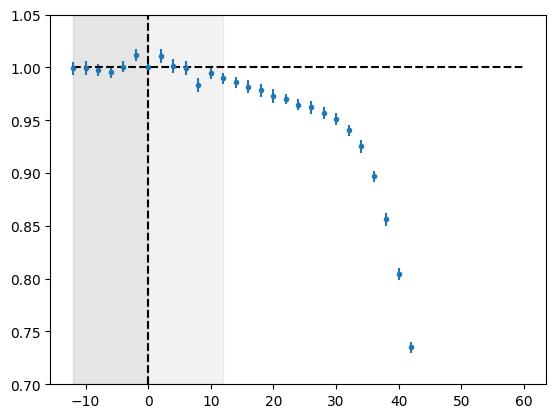

In [7]:
plt.errorbar(dx_190_6V, dy_190_6V_norm, yerr=dyErr_190_6V, fmt='.', label="190nm 6V")
plt.hlines(1, min(dx_190_6V), max(dx_190_6V), color='k', linestyle='--')
plt.vlines(0, 0.7, 1.05, color='k', linestyle='--')
plt.fill_between([0, min(dx_190_6V)], 0.7, 1.05, color='gray', alpha=0.2)
plt.fill_between([-min(dx_190_6V), 0], 0.7, 1.05, color='gray', alpha=0.1)

# plt.xlim(-15, 50)
plt.ylim(0.7, 1.05)
# plt.yscale('log')

In [8]:
# ## Rotating data points
# import numpy as np

# def rotate_points(x, y, x_center, y_center, angle):
#     # Convert the angle to radians
#     angle_rad = np.radians(angle)

#     # Create the rotation matrix
#     rotation_matrix = np.array([
#         [np.cos(angle_rad), -np.sin(angle_rad)],
#         [np.sin(angle_rad),  np.cos(angle_rad)]
#     ])

#     # Subtract the rotation center from the points
#     x -= x_center
#     y -= y_center

#     # Rotate the points
#     x_new, y_new = np.dot(rotation_matrix, [x, y])

#     # Add the rotation center back to the points
#     x_new += x_center
#     y_new += y_center

#     return x_new, y_new

In [9]:
# print("min X: ", min(dx_190_6V))

# xSymmetric = dx_190_6V[dx_190_6V <= -min(dx_190_6V)]
# ySymmetric = dy_190_6V_norm[dx_190_6V <= -min(dx_190_6V)]
# ySymmErrors = dyErr_190_6V[dx_190_6V <= -min(dx_190_6V)]

# plt.errorbar(xSymmetric, ySymmetric, yerr=ySymmErrors, fmt='r.', label="Symmetric 190nm 6V")

-----------------------------
Silicon data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/PDEhelpers/../opticsData/GoodMerged/silicon_crystalline_lithoAndSchinke_merged.txt
loaded and interpolated successfully.
-----------------------------
-----------------------------
Oxide data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/PDEhelpers/../opticsData/GoodMerged/silicon_dioxide-merged-clear.txt
loaded and interpolated successfully.
-----------------------------


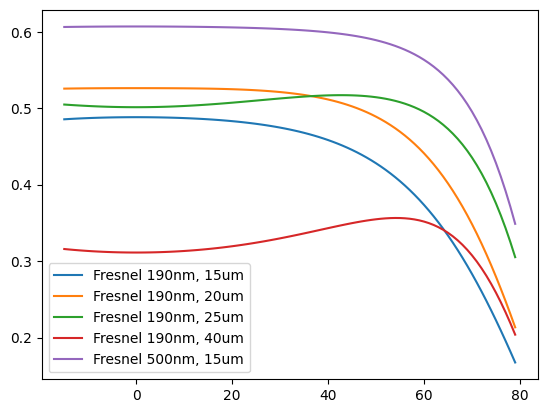

In [10]:
xAng = np.arange(-15, 80, 1)
photon_190 = PhotonInfo(wlen=190, theta_1=xAng)

thicknesses = [15, 20, 25, 40]
for t in thicknesses:
    plt.plot(xAng, photon_190.T_total_windowAndOxide(t), label="Fresnel 190nm, "+str(t)+"um")
    
photon_500 = PhotonInfo(wlen=500, theta_1=xAng)
plt.plot(xAng, photon_500.T_total_windowAndOxide(18), label="Fresnel 500nm, 15um")
plt.legend()
plt.show()

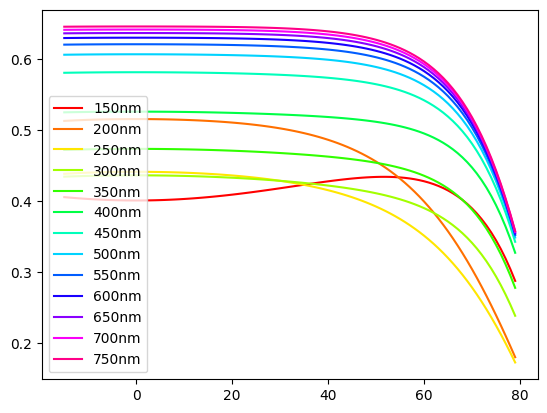

In [11]:
xAng = np.arange(-15, 80, 1)
tGood = 18

loopWlens = np.arange(150, 800, 50)
cmap = plt.get_cmap('hsv')
colors = [cmap(i) for i in np.linspace(0, 1, len(loopWlens)+1)]

for i, wl in enumerate(loopWlens):
    photon = PhotonInfo(wlen=wl, theta_1=xAng)
    tlabel=None if i % 2 == 0 else "Fresnel "+str(wl)+"nm"
    tlabel =str(wl)+"nm"
    plt.plot(xAng, photon.T_total_windowAndOxide(thick_oxide=tGood), color = colors[i], label=tlabel)
    
    
plt.legend()
plt.show()

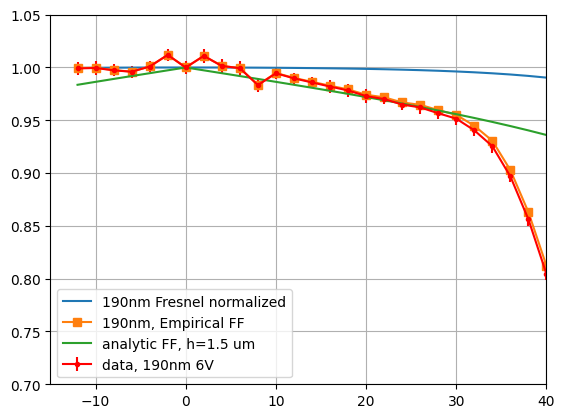

In [14]:
## plot together

photon_190 = PhotonInfo(wlen=500, theta_1=dx_190_6V)
zeroIndice = np.where(dx_190_6V == 0)[0][0]
ttGood=14

yFresnel_190 = photon_190.T_total_windowAndOxide(ttGood)
yFresnel_190_norm = yFresnel_190/yFresnel_190[zeroIndice]

# data
plt.errorbar(dx_190_6V, dy_190_6V_norm, yerr=dyErr_190_6V, marker=".", color="red", label="data, 190nm 6V")

# fresnel transmission
plt.plot(dx_190_6V, yFresnel_190_norm, label="190nm Fresnel normalized")

# data/fresnel (epirical FF)
fillFactorEmpirical = dy_190_6V_norm/yFresnel_190_norm
plt.plot(dx_190_6V, fillFactorEmpirical, marker = "s", label="190nm, Empirical FF")

height = 1.5
plt.plot(dx_190_6V, FF_theta_absolute(p, ffc, height, dx_190_6V)/FF, label="analytic FF, h={} um".format(height))



plt.legend()
plt.ylim(0.7, 1.05)
plt.xlim(-15, 40)
plt.grid()

plt.show()